# 1D-CNN for Non-Invasive Bilirubin Prediction in Neonatal Jaundice
## Paper: Makhloughi (2025) — Scientific Reports, DOI: 10.1038/s41598-025-96100-9

### Method Summary
- Extract **RGB + HSV** color channels from skin ROI of neonatal images
- Flatten pixel values into 1D time-series per channel
- Feed into a **1D-CNN** (4 Conv blocks → Dense → Regression/Classification)
- **Regression**: Predict TSB (mg/dL) — evaluated with RMSE, MAE, R²
- **Classification**: 3-class jaundice status (0–5, 5–10, >10 mg/dL)
- Dataset: **NeoJaundice** — 2235 images of 745 neonates

In [3]:
# ═══════════════════════════════════════════════════════════════════
# Cell 1: Imports & Configuration
# ═══════════════════════════════════════════════════════════════════
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Paths ──
IMAGE_DIR = '/Users/shubhbhateja/College/minor_project/images'
CSV_PATH  = '/Users/shubhbhateja/College/minor_project/NeoJaundice/chd_jaundice_published_2.csv'
SAVE_DIR  = '/Users/shubhbhateja/College/minor_project/development'
LOG_DIR   = os.path.join(SAVE_DIR, 'tensorboard_logs')

print(f'TensorFlow version: {tf.__version__}')
print(f'GPU available: {tf.config.list_physical_devices("GPU")}')
print(f'NumPy version: {np.__version__}')

TensorFlow version: 2.16.2
GPU available: []
NumPy version: 1.26.4


## Step 1: Load Dataset & Explore

Dataset shape: (2235, 8)
Columns: ['patient_id', 'image_idx', 'gender', 'gestational_age', 'age(day)', 'weight', 'blood(mg/dL)', 'Treatment']

Unique patients: 745
Images per patient: [3]

Target (TSB) statistics:
count    2235.000000
mean       11.206846
std         5.213196
min         0.000000
25%         7.400000
50%        11.800000
75%        15.100000
max        25.700000
Name: blood(mg/dL), dtype: float64

Class distribution (paper categories):
bilirubin_class
0-5 mg/dL      351
5-10 mg/dL     522
>10 mg/dL     1359
Name: count, dtype: int64


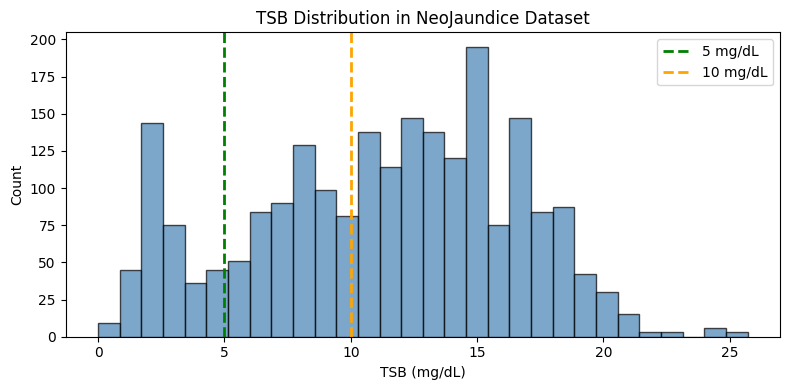

In [4]:
# ═══════════════════════════════════════════════════════════════════
# Cell 2: Load CSV & Explore
# ═══════════════════════════════════════════════════════════════════
df = pd.read_csv(CSV_PATH)
print(f'Dataset shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
print(f'\nUnique patients: {df["patient_id"].nunique()}')
print(f'Images per patient: {df.groupby("patient_id").size().unique()}')
print(f'\nTarget (TSB) statistics:')
print(df['blood(mg/dL)'].describe())

# Classification labels per paper: 0-5, 5-10, >10 mg/dL
bins = [0, 5, 10, float('inf')]
labels_text = ['0-5 mg/dL', '5-10 mg/dL', '>10 mg/dL']
df['bilirubin_class'] = pd.cut(df['blood(mg/dL)'], bins=bins, labels=labels_text, right=True)
print(f'\nClass distribution (paper categories):')
print(df['bilirubin_class'].value_counts().sort_index())

# Histogram of TSB values
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['blood(mg/dL)'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(5, color='green', linestyle='--', lw=2, label='5 mg/dL')
ax.axvline(10, color='orange', linestyle='--', lw=2, label='10 mg/dL')
ax.set_xlabel('TSB (mg/dL)')
ax.set_ylabel('Count')
ax.set_title('TSB Distribution in NeoJaundice Dataset')
ax.legend()
plt.tight_layout()
plt.show()

## Step 2: Preprocessing — Color Calibration + Skin ROI + Color Space Extraction

Per the paper:
1. **White balance** using the yellow calibration card in LAB space
2. **Skin ROI extraction** using HSV-based segmentation
3. Convert to **RGB + HSV** (the best-performing combination)
4. Flatten skin pixel values into a **1D sequence** (treated as time-series input)

In [5]:
# ═══════════════════════════════════════════════════════════════════
# Cell 3: Corrected Preprocessing Functions
# ═══════════════════════════════════════════════════════════════════

import cv2
import numpy as np
import os

# Skin ROI extraction matches img_cropping.ipynb (proven correct for your images)
LOWER_SKIN = np.array([0, 10, 60], dtype=np.uint8)
UPPER_SKIN = np.array([25, 200, 255], dtype=np.uint8)
SHRINK_TOP, SHRINK_BOTTOM = 15, 120
SHRINK_LEFT, SHRINK_RIGHT = 15, 15
TARGET_PIXELS = 4096   # fixed 1D sequence length


def extract_skin_region(image_rgb):
    """Extract skin region using img_cropping logic. Returns cropped RGB or None."""
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    skin_mask = cv2.inRange(hsv, LOWER_SKIN, UPPER_SKIN)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, kernel)
    skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)
    x1 = max(0, x + SHRINK_LEFT)
    y1 = max(0, y + SHRINK_TOP)
    x2 = min(image_rgb.shape[1], x + w - SHRINK_RIGHT)
    y2 = min(image_rgb.shape[0], y + h - SHRINK_BOTTOM)
    if x2 <= x1 or y2 <= y1:
        return None
    return image_rgb[y1:y2, x1:x2]


def make_fixed_sequence(features, target_pixels=TARGET_PIXELS):
    """Subsample or zero-pad to (target_pixels, 6)."""
    if features is None or features.shape[0] == 0:
        return np.zeros((target_pixels, 6), dtype=np.float32)
    n = features.shape[0]
    if n >= target_pixels:
        return features[np.linspace(0, n-1, target_pixels, dtype=int)]
    return np.concatenate([features,
                           np.zeros((target_pixels-n, 6), np.float32)], axis=0)


def preprocess_image(path, img_size=None, target_pixels=TARGET_PIXELS):
    """
    Full pipeline using img_cropping skin extraction:
      1. Load image, convert to RGB
      2. Extract skin region (HSV detection + shrink to remove borders)
      3. Get RGB+HSV from cropped region, flatten to (N, 6)
      4. Subsample/pad to fixed sequence length
    """
    image = cv2.imread(path)
    if image is None:
        return np.zeros((target_pixels, 6), dtype=np.float32)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    cropped = extract_skin_region(image_rgb)
    if cropped is None:
        return np.zeros((target_pixels, 6), dtype=np.float32)
    rgb_flat = cropped.reshape(-1, 3).astype(np.float32) / 255.0
    hsv_flat = cv2.cvtColor(cropped, cv2.COLOR_RGB2HSV).reshape(-1, 3).astype(np.float32) / 255.0
    features = np.concatenate([rgb_flat, hsv_flat], axis=1)
    return make_fixed_sequence(features, target_pixels)


# ── Quick verification (run this cell after replacing Cell 3) ─────────
sample_path = os.path.join(IMAGE_DIR, '0003-1.jpg')   # IMAGE_DIR defined in Cell 2
seq = preprocess_image(sample_path)
nz  = int(np.sum(seq.sum(axis=1) > 0))
print(f"Shape        : {seq.shape}   (expected: ({TARGET_PIXELS}, 6))")
print(f"Value range  : [{seq.min():.3f}, {seq.max():.3f}]   (expected: [0.0, 1.0])")
print(f"Non-zero rows: {nz}/{TARGET_PIXELS} ({nz/TARGET_PIXELS*100:.1f}%)")
print()
print("PASS ✅" if (nz > 100 and seq.max() <= 1.0) else "FAIL ❌ — check path or image")


Shape        : (4096, 6)   (expected: (4096, 6))
Value range  : [0.000, 0.965]   (expected: [0.0, 1.0])
Non-zero rows: 4096/4096 (100.0%)

PASS ✅


Pipeline visualization for 3 sample images:



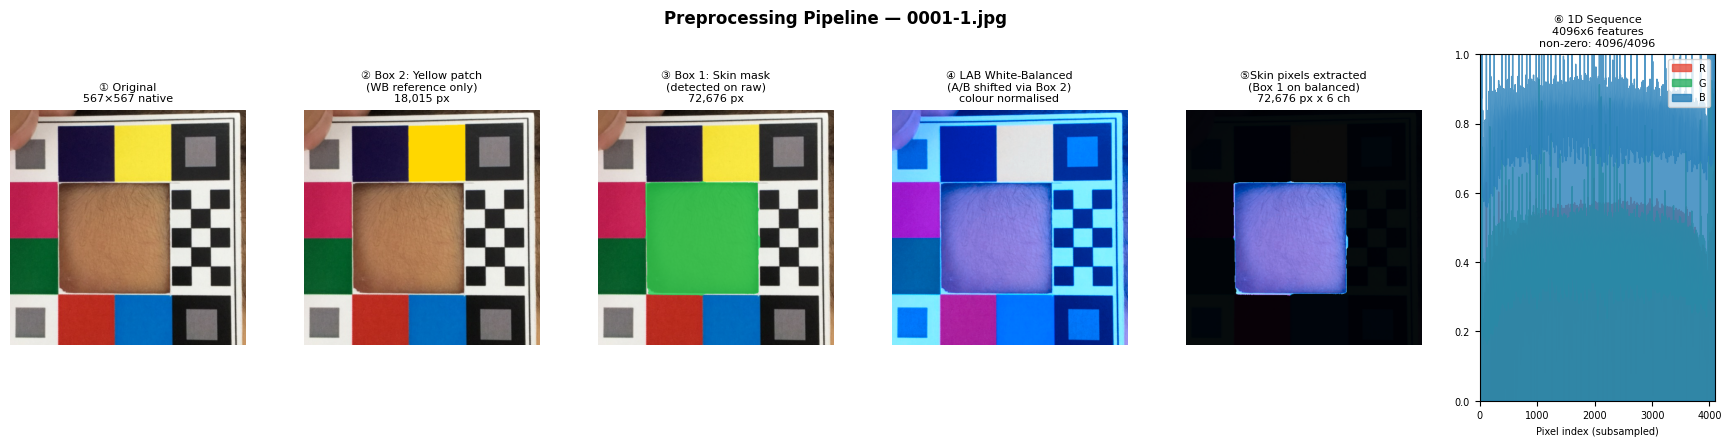

  0001-1.jpg: skin=72,676px  nz=4096/4096  mean R=0.450 G=0.452 B=0.839


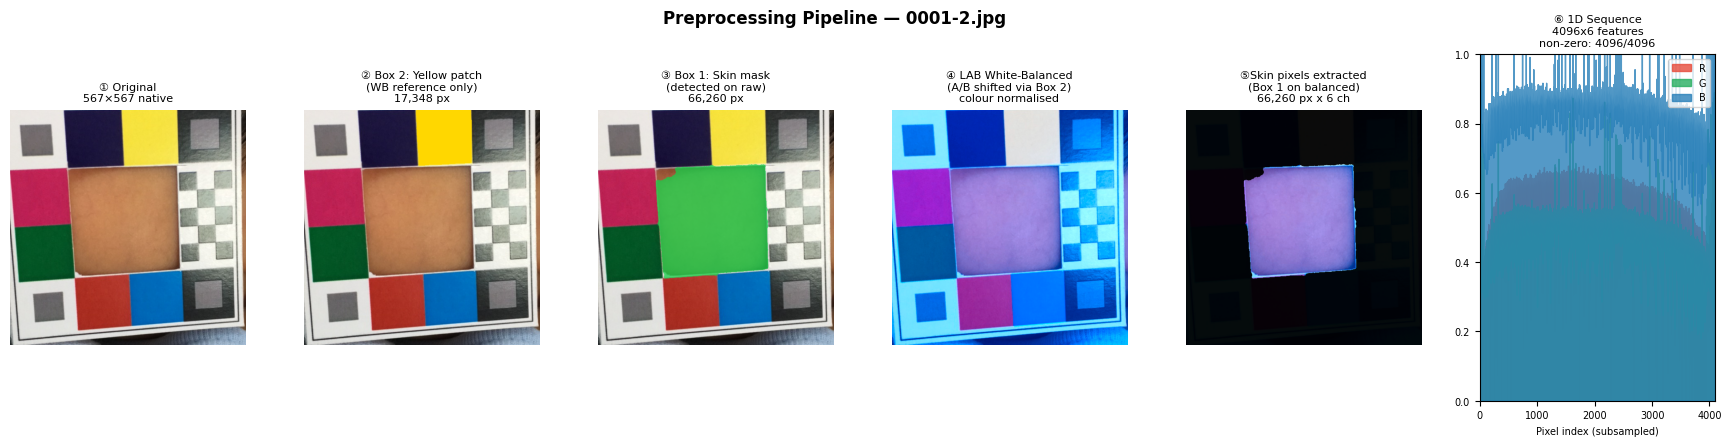

  0001-2.jpg: skin=66,260px  nz=4096/4096  mean R=0.556 G=0.491 B=0.846


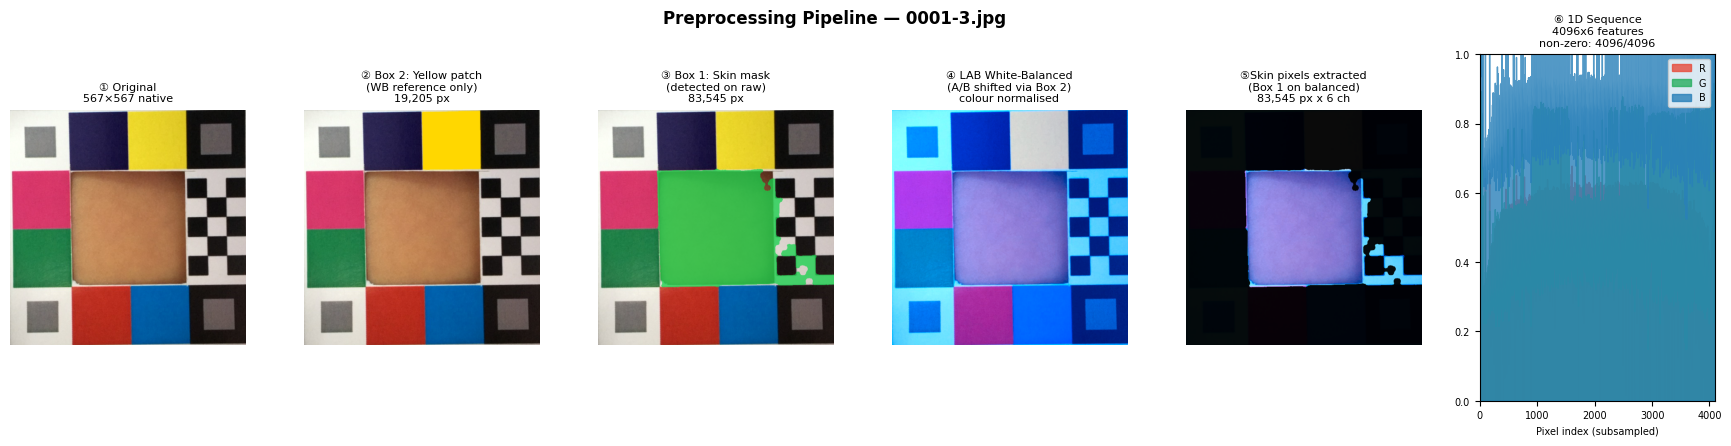

  0001-3.jpg: skin=83,545px  nz=4096/4096  mean R=0.487 G=0.505 B=0.853


In [6]:
# ═══════════════════════════════════════════════════════════════════
# Cell 3b: Step-by-Step Pipeline Visualization
# Self-contained — imports directly from preprocess_v2.py
# so it can be run independently without needing Cell 3 first.
# ═══════════════════════════════════════════════════════════════════

import os, sys, cv2, numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ── Import preprocessing functions (works even if Cell 3 not yet run) ──
sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(".")),
                                "minor_project", "development"))
# Absolute fallback path
_DEV = "/Users/shubhbhateja/College/minor_project/development"
if _DEV not in sys.path:
    sys.path.insert(0, _DEV)

from preprocess_v2 import (
    detect_yellow_patch,
    detect_skin_roi_mask,
    lab_white_balance,
    extract_color_features,
    make_fixed_sequence,
    TARGET_PIXELS,
)


def visualize_pipeline(img_path, title="Pipeline"):
    """Show all 6 preprocessing steps for one image side-by-side."""
    raw     = cv2.imread(img_path)
    raw_rgb = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)

    # ── Pipeline ──────────────────────────────────────────────────
    _, yp_mask = detect_yellow_patch(raw)        # Box 2: yellow patch (tuple!)
    sm         = detect_skin_roi_mask(raw)        # Box 1: skin window (on RAW)
    balanced   = lab_white_balance(raw, yp_mask)  # LAB white balance
    bal_rgb    = cv2.cvtColor(balanced, cv2.COLOR_BGR2RGB)
    features   = extract_color_features(balanced, sm)
    seq        = make_fixed_sequence(features)

    n_y = int(np.sum(yp_mask > 0)) if yp_mask is not None else 0
    n_s = int(np.sum(sm > 0))      if sm       is not None else 0
    nz  = int(np.sum(seq.sum(axis=1) > 0))

    # ── Plot ──────────────────────────────────────────────────────
    fig = plt.figure(figsize=(22, 4.5))
    gs  = gridspec.GridSpec(1, 6, figure=fig, wspace=0.25)
    fig.suptitle(title, fontsize=12, fontweight='bold')

    # ① Original
    ax = fig.add_subplot(gs[0])
    ax.imshow(raw_rgb); ax.axis('off')
    ax.set_title("① Original\n567×567 native", fontsize=8)

    # ② Box 2: yellow patch
    ov = raw_rgb.copy()
    if yp_mask is not None:
        ov[yp_mask > 0] = [255, 215, 0]
    ax = fig.add_subplot(gs[1])
    ax.imshow(ov); ax.axis('off')
    ax.set_title(f"② Box 2: Yellow patch\n(WB reference only)\n{n_y:,} px", fontsize=8)

    # ③ Box 1: skin mask on raw
    ov2 = raw_rgb.copy()
    if sm is not None:
        ov2[sm > 0] = (ov2[sm > 0]*0.25 + np.array([20,210,75])*0.75).astype(np.uint8)
    ax = fig.add_subplot(gs[2])
    ax.imshow(ov2); ax.axis('off')
    ax.set_title(f"③ Box 1: Skin mask\n(detected on raw)\n{n_s:,} px", fontsize=8)

    # ④ White-balanced image
    ax = fig.add_subplot(gs[3])
    ax.imshow(bal_rgb); ax.axis('off')
    ax.set_title("④ LAB White-Balanced\n(A/B shifted via Box 2)\ncolour normalised", fontsize=8)

    # ⑤ Isolated skin pixels
    dark = (bal_rgb * 0.05).astype(np.uint8)
    iso  = dark.copy()
    if sm is not None:
        iso[sm > 0] = bal_rgb[sm > 0]
    ax = fig.add_subplot(gs[4])
    ax.imshow(iso); ax.axis('off')
    ax.set_title(f"⑤Skin pixels extracted\n(Box 1 on balanced)\n{n_s:,} px x 6 ch", fontsize=8)

    # ⑥ 1D sequence (R/G/B shown)
    x = np.arange(seq.shape[0])
    ax = fig.add_subplot(gs[5])
    ax.fill_between(x, seq[:,0], alpha=0.8, color='#E74C3C', label='R')
    ax.fill_between(x, seq[:,1], alpha=0.8, color='#27AE60', label='G')
    ax.fill_between(x, seq[:,2], alpha=0.8, color='#2980B9', label='B')
    ax.set_xlim(0, seq.shape[0]); ax.set_ylim(0, 1)
    ax.set_title(f"⑥ 1D Sequence\n4096x6 features\nnon-zero: {nz}/{seq.shape[0]}", fontsize=8)
    ax.set_xlabel("Pixel index (subsampled)", fontsize=7)
    ax.legend(fontsize=7, loc='upper right')
    ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

    r_m = seq[:,0][seq[:,0]>0].mean() if nz > 0 else 0
    g_m = seq[:,1][seq[:,1]>0].mean() if nz > 0 else 0
    b_m = seq[:,2][seq[:,2]>0].mean() if nz > 0 else 0
    print(f"  {img_path.split('/')[-1]}: skin={n_s:,}px  nz={nz}/{TARGET_PIXELS}"
          f"  mean R={r_m:.3f} G={g_m:.3f} B={b_m:.3f}")


# ── Visualise first 3 images ──────────────────────────────────────
print("Pipeline visualization for 3 sample images:\n")
for _fname in sorted(os.listdir(IMAGE_DIR))[:3]:
    visualize_pipeline(
        os.path.join(IMAGE_DIR, _fname),
        title=f"Preprocessing Pipeline — {_fname}"
    )


## Step 3: Load Full Dataset

In [7]:
# ═══════════════════════════════════════════════════════════════════
# Cell 4: Load All Images → (N, 4096, 6) array
# ═══════════════════════════════════════════════════════════════════
TARGET_PIXELS = 4096  # Fixed 1D sequence length

X_all = []
y_reg_all = []       # TSB values (regression target)
y_cls_all = []       # Classification labels
patient_ids = []
skipped = 0

print('Loading and preprocessing images...')
t0 = time.time()

for idx, row in df.iterrows():
    img_name = str(row['image_idx'])
    if not img_name.endswith(('.jpg', '.jpeg', '.png')):
        img_name += '.jpg'
    img_path = os.path.join(IMAGE_DIR, img_name)

    if not os.path.exists(img_path):
        skipped += 1
        continue

    try:
        features = preprocess_image(img_path, target_pixels=TARGET_PIXELS)
        # Skip if skin extraction failed (all zeros)
        if np.allclose(features, 0.0):
            skipped += 1
            continue
        X_all.append(features)
        y_reg_all.append(row['blood(mg/dL)'])

        # Paper classification: 0-5 → 0, 5-10 → 1, >10 → 2
        tsb = row['blood(mg/dL)']
        if tsb <= 5:
            cls_label = 0
        elif tsb <= 10:
            cls_label = 1
        else:
            cls_label = 2
        y_cls_all.append(cls_label)
        patient_ids.append(row['patient_id'])

        if len(X_all) % 500 == 0:
            print(f'  Loaded {len(X_all)} samples...')
    except Exception as e:
        print(f'  Error processing {img_name}: {e}')
        skipped += 1

elapsed = time.time() - t0

X_all = np.array(X_all, dtype=np.float32)
y_reg_all = np.array(y_reg_all, dtype=np.float32)
y_cls_all = np.array(y_cls_all, dtype=np.int32)
patient_ids = np.array(patient_ids)

print(f'\nLoaded {len(X_all)} samples in {elapsed:.1f}s (skipped {skipped})')
print(f'X shape:       {X_all.shape}  → (samples, {TARGET_PIXELS}, 6)')
print(f'y_reg shape:   {y_reg_all.shape}')
print(f'y_cls shape:   {y_cls_all.shape}')
print(f'Value range:   [{X_all.min():.3f}, {X_all.max():.3f}]')

# Class distribution
for i, label in enumerate(['0-5 mg/dL', '5-10 mg/dL', '>10 mg/dL']):
    count = np.sum(y_cls_all == i)
    print(f'  Class {i} ({label}): {count} samples ({count/len(y_cls_all)*100:.1f}%)')

Loading and preprocessing images...
  Loaded 500 samples...
  Loaded 1000 samples...
  Loaded 1500 samples...
  Loaded 2000 samples...

Loaded 2234 samples in 8.7s (skipped 1)
X shape:       (2234, 4096, 6)  → (samples, 4096, 6)
y_reg shape:   (2234,)
y_cls shape:   (2234,)
Value range:   [0.000, 1.000]
  Class 0 (0-5 mg/dL): 354 samples (15.8%)
  Class 1 (5-10 mg/dL): 522 samples (23.4%)
  Class 2 (>10 mg/dL): 1358 samples (60.8%)


## Step 4: Patient-Level Train/Val/Test Split (70/10/20)

Per the paper: 70% train, 10% validation, 20% test.  
We split by **patient_id** to prevent data leakage (each patient has 3 images with identical targets).

In [8]:
# ═══════════════════════════════════════════════════════════════════
# Cell 5: Patient-Level Split
# ═══════════════════════════════════════════════════════════════════
unique_patients = np.unique(patient_ids)

# Get one classification label per patient (same for all 3 images)
patient_cls = {pid: y_cls_all[patient_ids == pid][0] for pid in unique_patients}
patient_cls_labels = np.array([patient_cls[pid] for pid in unique_patients])

# 70% train / 30% temp
train_pats, temp_pats, train_cls, temp_cls = train_test_split(
    unique_patients, patient_cls_labels,
    test_size=0.3, random_state=SEED, stratify=patient_cls_labels
)

# 10% val / 20% test (from the 30% temp)
val_pats, test_pats, _, _ = train_test_split(
    temp_pats, temp_cls,
    test_size=2/3, random_state=SEED, stratify=temp_cls
)

# Boolean masks
train_mask = np.isin(patient_ids, train_pats)
val_mask   = np.isin(patient_ids, val_pats)
test_mask  = np.isin(patient_ids, test_pats)

# Split arrays
X_train, X_val, X_test = X_all[train_mask], X_all[val_mask], X_all[test_mask]
y_reg_train, y_reg_val, y_reg_test = y_reg_all[train_mask], y_reg_all[val_mask], y_reg_all[test_mask]
y_cls_train, y_cls_val, y_cls_test = y_cls_all[train_mask], y_cls_all[val_mask], y_cls_all[test_mask]

# Verify no patient leakage
assert len(set(patient_ids[train_mask]) & set(patient_ids[val_mask])) == 0
assert len(set(patient_ids[train_mask]) & set(patient_ids[test_mask])) == 0
assert len(set(patient_ids[val_mask]) & set(patient_ids[test_mask])) == 0

print('Patient-level split (no data leakage):')
print(f'  Train: {len(train_pats):>4} patients → {train_mask.sum():>5} samples ({train_mask.sum()/len(X_all)*100:.1f}%)')
print(f'  Val:   {len(val_pats):>4} patients → {val_mask.sum():>5} samples ({val_mask.sum()/len(X_all)*100:.1f}%)')
print(f'  Test:  {len(test_pats):>4} patients → {test_mask.sum():>5} samples ({test_mask.sum()/len(X_all)*100:.1f}%)')
print('  ✅ No patient leakage verified')

# Class distribution per split
for name, labels in [('Train', y_cls_train), ('Val', y_cls_val), ('Test', y_cls_test)]:
    u, c = np.unique(labels, return_counts=True)
    dist = {['0-5', '5-10', '>10'][i]: n for i, n in zip(u, c)}
    print(f'  {name} class distribution: {dist}')

Patient-level split (no data leakage):
  Train:  521 patients →  1562 samples (69.9%)
  Val:     74 patients →   222 samples (9.9%)
  Test:   150 patients →   450 samples (20.1%)
  ✅ No patient leakage verified
  Train class distribution: {'0-5': 246, '5-10': 366, '>10': 950}
  Val class distribution: {'0-5': 36, '5-10': 51, '>10': 135}
  Test class distribution: {'0-5': 72, '5-10': 105, '>10': 273}


## Step 5: Build 1D-CNN Model (Paper Table 2 Architecture)

Architecture from the paper:
- **Conv1D(32, k=3, same) → ReLU → MaxPool(2)**
- **Conv1D(64, k=3, same) → ReLU → MaxPool(2)**
- **Conv1D(128, k=3, same) → ReLU → MaxPool(2)**
- **Conv1D(128, k=3, same) → ReLU → MaxPool(2)**
- **Flatten → Dense(256) → Dropout(0.3) → Dense(128) → Dropout(0.5) → Output(1)**

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# Cell 6: Build 1D-CNN for Regression (Paper Table 2)
# ═══════════════════════════════════════════════════════════════════

def build_1dcnn_regression(input_shape):
    """1D-CNN architecture from Makhloughi (2025) Table 2.
    Input: (seq_len, 6) — RGB+HSV skin pixel time-series.
    Output: single scalar — predicted TSB (mg/dL)."""

    inp = tf.keras.Input(shape=input_shape, name='color_input')

    # Block 1: Conv1D(32, k=3) → ReLU → MaxPool(2)
    x = tf.keras.layers.Conv1D(32, 3, padding='same', activation='relu', name='conv1d_1')(inp)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_1')(x)

    # Block 2: Conv1D(64, k=3) → ReLU → MaxPool(2)
    x = tf.keras.layers.Conv1D(64, 3, padding='same', activation='relu', name='conv1d_2')(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_2')(x)

    # Block 3: Conv1D(128, k=3) → ReLU → MaxPool(2)
    x = tf.keras.layers.Conv1D(128, 3, padding='same', activation='relu', name='conv1d_3')(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_3')(x)

    # Block 4: Conv1D(128, k=3) → ReLU → MaxPool(2)
    x = tf.keras.layers.Conv1D(128, 3, padding='same', activation='relu', name='conv1d_4')(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_4')(x)

    # Flatten → Dense layers
    x = tf.keras.layers.Flatten(name='flatten')(x)
    x = tf.keras.layers.Dense(256, activation='relu', name='dense_1')(x)
    x = tf.keras.layers.Dropout(0.3, name='dropout_1')(x)
    x = tf.keras.layers.Dense(128, activation='relu', name='dense_2')(x)
    x = tf.keras.layers.Dropout(0.5, name='dropout_2')(x)

    # Output: regression (linear activation)
    out = tf.keras.layers.Dense(1, activation='linear', name='tsb_output')(x)

    model = tf.keras.Model(inputs=inp, outputs=out, name='1DCNN_Regression')
    return model


# Build regression model
reg_model = build_1dcnn_regression(input_shape=X_train.shape[1:])
reg_model.summary()
print(f'\nTotal parameters: {reg_model.count_params():,}')

Model: "1DCNN_Regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ color_input (InputLayer)        │ (None, 4096, 6)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4096, 32)       │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling1D)        │ (None, 2048, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 2048, 64)       │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling1D)        │ (None, 1024, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 1024, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_3 (MaxPooling1D)        │ (None, 512, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 512, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_4 (MaxPooling1D)        │ (None, 256, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tsb_output (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,502,689 (32.44 MB)

 Trainable params: 8,502,689 (32.44 MB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 8,502,689


## Step 6: Compile & Train Regression Model

Paper hyperparameters (Table 4):
- **Optimizer**: Adam, learning rate decayed from 0.01
- **Loss**: MSE
- **Batch size**: 32
- **Epochs**: 150 (with early stopping)
- **ReduceLROnPlateau** for learning rate decay

In [10]:
# ═══════════════════════════════════════════════════════════════════
# Cell 7: Compile & Train Regression Model
# ═══════════════════════════════════════════════════════════════════
EPOCHS = 150
BATCH_SIZE = 32
INITIAL_LR = 0.01

reg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR),
    loss='mse',
    metrics=['mae']
)

os.makedirs(LOG_DIR, exist_ok=True)

callbacks_reg = [
    tf.keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, 'regression'), write_graph=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, 'best_1dcnn_regression.keras'),
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    )
]

print(f'Training regression model...')
print(f'  Epochs: {EPOCHS} (early stopping patience=20)')
print(f'  Batch size: {BATCH_SIZE}')
print(f'  Initial LR: {INITIAL_LR} (ReduceLR patience=8, factor=0.5)')
print(f'  Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

t_start = time.time()

history_reg = reg_model.fit(
    X_train, y_reg_train,
    validation_data=(X_val, y_reg_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_reg,
    verbose=1
)

t_elapsed = time.time() - t_start
n_epochs = len(history_reg.history['loss'])

print(f'\n{"="*60}')
print(f'Regression training completed in {n_epochs} epochs ({t_elapsed:.0f}s = {t_elapsed/60:.1f}min)')
print(f'  Best val_loss: {min(history_reg.history["val_loss"]):.4f}')
print(f'  Final train_loss: {history_reg.history["loss"][-1]:.4f}')

Training regression model...
  Epochs: 150 (early stopping patience=20)
  Batch size: 32
  Initial LR: 0.01 (ReduceLR patience=8, factor=0.5)
  Train: 1562 | Val: 222 | Test: 450
Epoch 1/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 4347.7261 - mae: 23.2441 - val_loss: 31.6625 - val_mae: 4.7119 - learning_rate: 0.0100
Epoch 2/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 37.3310 - mae: 5.0643 - val_loss: 42.1724 - val_mae: 5.3866 - learning_rate: 0.0100
Epoch 3/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 37.6775 - mae: 5.0840 - val_loss: 38.3206 - val_mae: 5.1508 - learning_rate: 0.0100
Epoch 4/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - loss: 35.5626 - mae: 4.9341 - val_loss: 33.4886 - val_mae: 4.8153 - learning_rate: 0.0100
Epoch 5/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 34.3448 - mae: 4.8760 - val_loss: 41.9566 - val_mae: 5.3823 - learning_rate: 0.0100
Epoch 6/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - loss: 37.5330 - mae: 5.0553 - val_loss: 33.2

## Step 7: Evaluate Regression on Test Set

In [11]:
# ═══════════════════════════════════════════════════════════════════
# Cell 8: Regression Evaluation
# ═══════════════════════════════════════════════════════════════════

# Load best model
best_reg_path = os.path.join(SAVE_DIR, 'best_1dcnn_regression.keras')
if os.path.exists(best_reg_path):
    reg_model = tf.keras.models.load_model(best_reg_path)
    print('✅ Loaded best regression model from checkpoint')

# Predict on test set
y_pred_reg = reg_model.predict(X_test).flatten()

# Metrics
mse_test  = mean_squared_error(y_reg_test, y_pred_reg)
rmse_test = np.sqrt(mse_test)
mae_test  = mean_absolute_error(y_reg_test, y_pred_reg)
r2_test   = r2_score(y_reg_test, y_pred_reg)

print('\n' + '='*60)
print('📊 REGRESSION RESULTS (Test Set) — RGB+HSV 1D-CNN')
print('='*60)
print(f'  RMSE:  {rmse_test:.4f} mg/dL   (paper: 1.13)')
print(f'  MAE:   {mae_test:.4f} mg/dL   (paper: 0.89)')
print(f'  R²:    {r2_test:.4f}          (paper: 0.91)')
print('='*60)

✅ Loaded best regression model from checkpoint
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

📊 REGRESSION RESULTS (Test Set) — RGB+HSV 1D-CNN
  RMSE:  5.1446 mg/dL   (paper: 1.13)
  MAE:   4.1663 mg/dL   (paper: 0.89)
  R²:    -0.0319          (paper: 0.91)


## Step 8: Regression Visualizations

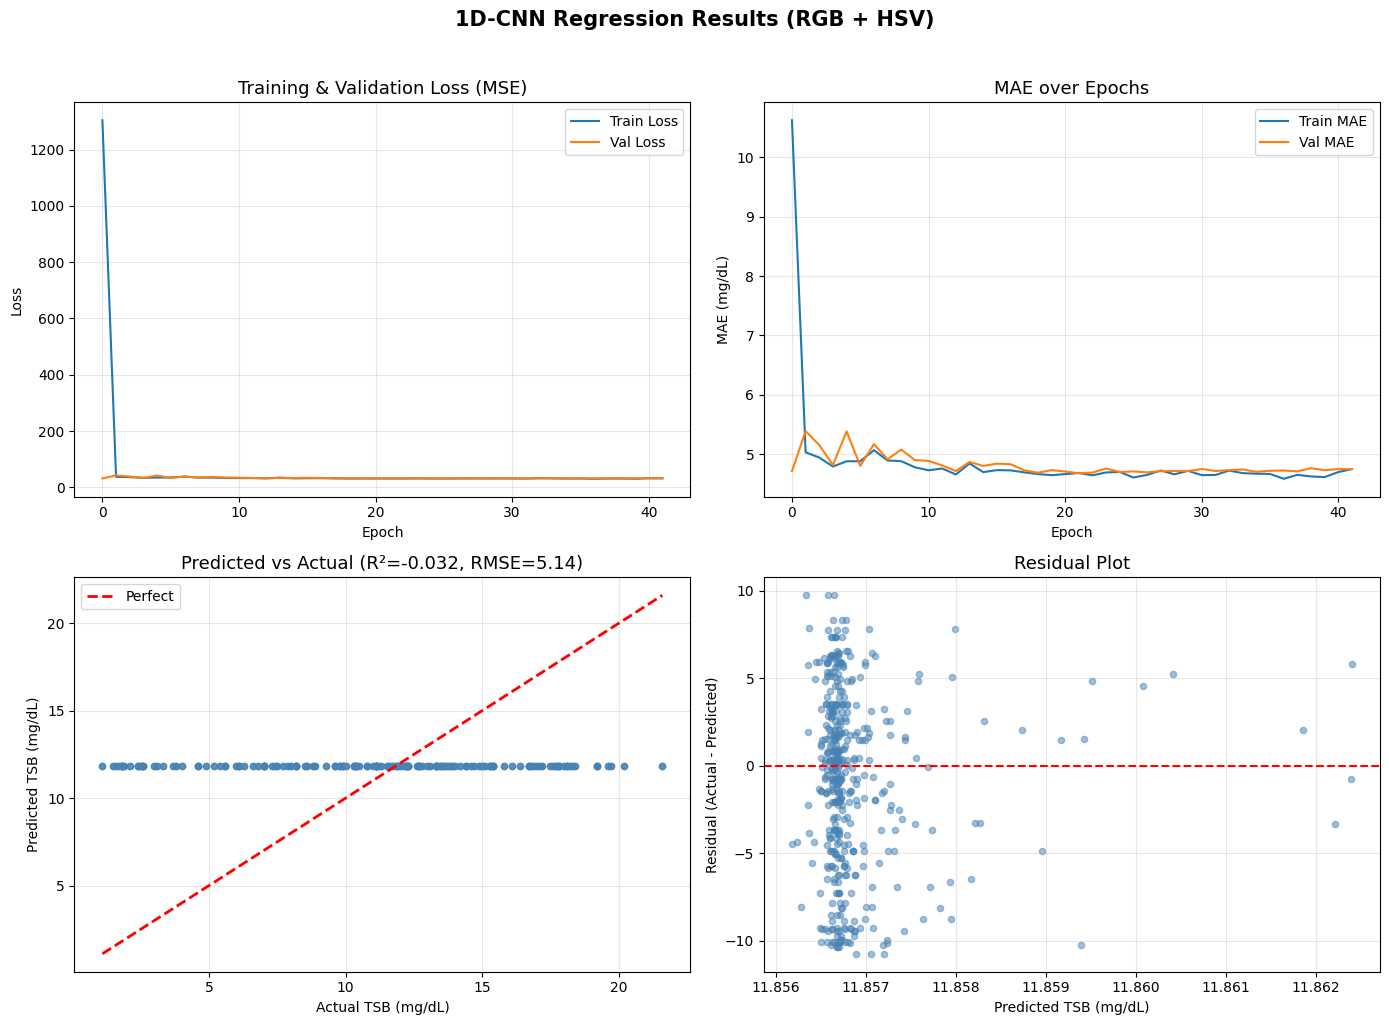

In [12]:
# ═══════════════════════════════════════════════════════════════════
# Cell 9: Regression Visualizations
# ═══════════════════════════════════════════════════════════════════
h_reg = history_reg.history

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Training Loss
axes[0, 0].plot(h_reg['loss'], label='Train Loss', linewidth=1.5)
axes[0, 0].plot(h_reg['val_loss'], label='Val Loss', linewidth=1.5)
axes[0, 0].set_title('Training & Validation Loss (MSE)', fontsize=13)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE
axes[0, 1].plot(h_reg['mae'], label='Train MAE', linewidth=1.5)
axes[0, 1].plot(h_reg['val_mae'], label='Val MAE', linewidth=1.5)
axes[0, 1].set_title('MAE over Epochs', fontsize=13)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE (mg/dL)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Predicted vs Actual
axes[1, 0].scatter(y_reg_test, y_pred_reg, alpha=0.5, s=20, c='steelblue')
lims = [min(y_reg_test.min(), y_pred_reg.min()), max(y_reg_test.max(), y_pred_reg.max())]
axes[1, 0].plot(lims, lims, 'r--', lw=2, label='Perfect')
axes[1, 0].set_xlabel('Actual TSB (mg/dL)')
axes[1, 0].set_ylabel('Predicted TSB (mg/dL)')
axes[1, 0].set_title(f'Predicted vs Actual (R²={r2_test:.3f}, RMSE={rmse_test:.2f})', fontsize=13)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Residual Plot
residuals = y_reg_test - y_pred_reg
axes[1, 1].scatter(y_pred_reg, residuals, alpha=0.5, s=20, c='steelblue')
axes[1, 1].axhline(0, color='r', linestyle='--', lw=1.5)
axes[1, 1].set_xlabel('Predicted TSB (mg/dL)')
axes[1, 1].set_ylabel('Residual (Actual - Predicted)')
axes[1, 1].set_title('Residual Plot', fontsize=13)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('1D-CNN Regression Results (RGB + HSV)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Step 9: Build & Train Classification Model

Per the paper, the same 1D-CNN architecture is adapted for **3-class classification**:
- Class 0: 0–5 mg/dL
- Class 1: 5–10 mg/dL  
- Class 2: >10 mg/dL

Only the final dense layer changes to softmax with 3 outputs.

In [13]:
# ═══════════════════════════════════════════════════════════════════
# Cell 10: Build & Train Classification Model
# ═══════════════════════════════════════════════════════════════════

def build_1dcnn_classification(input_shape, n_classes=3):
    """1D-CNN adapted for classification (paper Section: Results).
    Same architecture as regression but with softmax output."""

    inp = tf.keras.Input(shape=input_shape, name='color_input')

    # Identical conv blocks as regression model
    x = tf.keras.layers.Conv1D(32, 3, padding='same', activation='relu', name='conv1d_1')(inp)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_1')(x)

    x = tf.keras.layers.Conv1D(64, 3, padding='same', activation='relu', name='conv1d_2')(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_2')(x)

    x = tf.keras.layers.Conv1D(128, 3, padding='same', activation='relu', name='conv1d_3')(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_3')(x)

    x = tf.keras.layers.Conv1D(128, 3, padding='same', activation='relu', name='conv1d_4')(x)
    x = tf.keras.layers.MaxPooling1D(pool_size=2, padding='same', name='maxpool_4')(x)

    x = tf.keras.layers.Flatten(name='flatten')(x)
    x = tf.keras.layers.Dense(256, activation='relu', name='dense_1')(x)
    x = tf.keras.layers.Dropout(0.3, name='dropout_1')(x)
    x = tf.keras.layers.Dense(128, activation='relu', name='dense_2')(x)
    x = tf.keras.layers.Dropout(0.5, name='dropout_2')(x)

    # Output: classification (softmax)
    out = tf.keras.layers.Dense(n_classes, activation='softmax', name='cls_output')(x)

    model = tf.keras.Model(inputs=inp, outputs=out, name='1DCNN_Classification')
    return model


# Build & compile
cls_model = build_1dcnn_classification(input_shape=X_train.shape[1:])

# Compute class weights for imbalanced classes
from sklearn.utils.class_weight import compute_class_weight
classes = np.array([0, 1, 2])
cw = compute_class_weight('balanced', classes=classes, y=y_cls_train)
class_weight_dict = {i: w for i, w in enumerate(cw)}
print(f'Class weights: {class_weight_dict}')

cls_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_cls = [
    tf.keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, 'classification'), write_graph=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, 'best_1dcnn_classification.keras'),
        monitor='val_accuracy',
        save_best_only=True,
        verbose=0
    )
]

cls_model.summary()

print(f'\nTraining classification model...')
t_start = time.time()

history_cls = cls_model.fit(
    X_train, y_cls_train,
    validation_data=(X_val, y_cls_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=callbacks_cls,
    verbose=1
)

t_cls = time.time() - t_start
n_cls_epochs = len(history_cls.history['loss'])

print(f'\n{"="*60}')
print(f'Classification training completed in {n_cls_epochs} epochs ({t_cls:.0f}s = {t_cls/60:.1f}min)')
print(f'  Best val_accuracy: {max(history_cls.history["val_accuracy"]):.4f}')
print(f'  Final train_accuracy: {history_cls.history["accuracy"][-1]:.4f}')

Class weights: {0: 2.116531165311653, 1: 1.4225865209471766, 2: 0.5480701754385965}


Model: "1DCNN_Classification"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ color_input (InputLayer)        │ (None, 4096, 6)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4096, 32)       │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling1D)        │ (None, 2048, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 2048, 64)       │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling1D)        │ (None, 1024, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 1024, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_3 (MaxPooling1D)        │ (None, 512, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 512, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_4 (MaxPooling1D)        │ (None, 256, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cls_output (Dense)              │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,502,947 (32.44 MB)

 Trainable params: 8,502,947 (32.44 MB)

 Non-trainable params: 0 (0.00 B)


Training classification model...
Epoch 1/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.2636 - loss: 2.4472 - val_accuracy: 0.2297 - val_loss: 1.1124 - learning_rate: 0.0100
Epoch 2/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.2809 - loss: 1.0873 - val_accuracy: 0.2297 - val_loss: 1.1117 - learning_rate: 0.0100
Epoch 3/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.2467 - loss: 1.0846 - val_accuracy: 0.1622 - val_loss: 1.1031 - learning_rate: 0.0100
Epoch 4/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.3315 - loss: 1.0842 - val_accuracy: 0.1622 - val_loss: 1.1027 - learning_rate: 0.0100
Epoch 5/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.3037 - loss: 1.0845 - val_accuracy: 0.2297 - val_loss: 1.0995 - learning_rate: 0.0100
Epoch 6/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.3997 - loss: 1.0842 - val_accuracy: 0.2297 - val_loss: 1.1020 - learning_rate: 0.0100
Epoch 7/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - 

KeyboardInterrupt: 

## Step 10: Evaluate Classification on Test Set

## TensorBoard & Training Graphs

**View logs in TensorBoard** (run in terminal):
```bash
tensorboard --logdir=/Users/shubhbhateja/College/minor_project/development/tensorboard_logs --port=6006
```
Then open http://localhost:6006 in your browser.

**Install TensorBoard** (if needed): `pip install tensorboard`

Saved: /Users/shubhbhateja/College/minor_project/development/training_curves.png


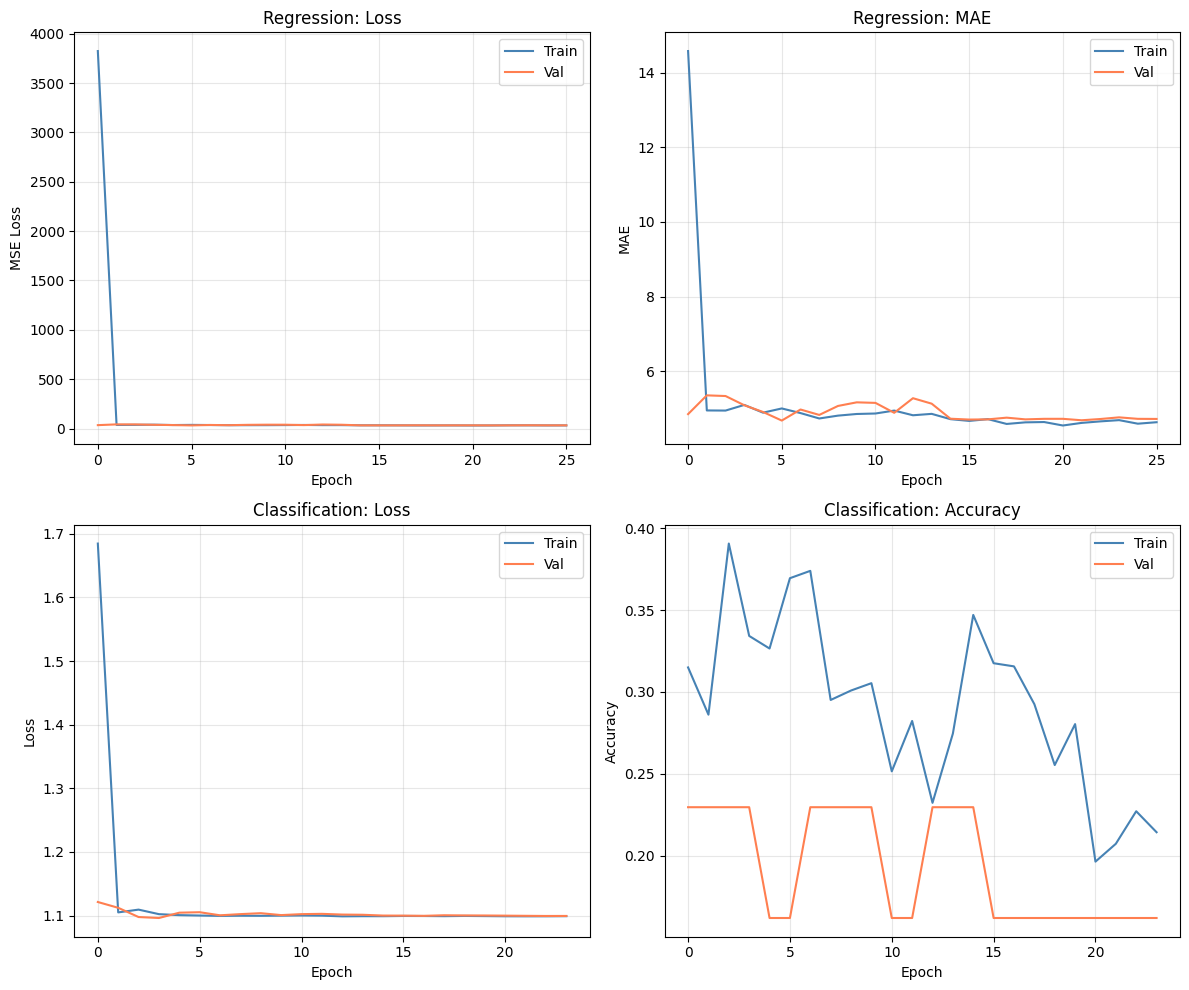

In [ ]:
# Create and save training curves from history (run after both models are trained)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Regression: Loss
ax = axes[0, 0]
ax.plot(history_reg.history['loss'], label='Train', color='steelblue')
ax.plot(history_reg.history['val_loss'], label='Val', color='coral')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('Regression: Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# Regression: MAE
ax = axes[0, 1]
ax.plot(history_reg.history['mae'], label='Train', color='steelblue')
ax.plot(history_reg.history['val_mae'], label='Val', color='coral')
ax.set_xlabel('Epoch')
ax.set_ylabel('MAE')
ax.set_title('Regression: MAE')
ax.legend()
ax.grid(True, alpha=0.3)

# Classification: Loss
ax = axes[1, 0]
ax.plot(history_cls.history['loss'], label='Train', color='steelblue')
ax.plot(history_cls.history['val_loss'], label='Val', color='coral')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Classification: Loss')
ax.legend()
ax.grid(True, alpha=0.3)

# Classification: Accuracy
ax = axes[1, 1]
ax.plot(history_cls.history['accuracy'], label='Train', color='steelblue')
ax.plot(history_cls.history['val_accuracy'], label='Val', color='coral')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('Classification: Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
print(f'Saved: {os.path.join(SAVE_DIR, "training_curves.png")}')
plt.show()

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# Cell 11: Classification Evaluation
# ═══════════════════════════════════════════════════════════════════

# Load best classification model
best_cls_path = os.path.join(SAVE_DIR, 'best_1dcnn_classification.keras')
if os.path.exists(best_cls_path):
    cls_model = tf.keras.models.load_model(best_cls_path)
    print('✅ Loaded best classification model from checkpoint')

# Predict
y_pred_cls_prob = cls_model.predict(X_test)
y_pred_cls = np.argmax(y_pred_cls_prob, axis=1)

# Metrics
accuracy = accuracy_score(y_cls_test, y_pred_cls)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_cls_test, y_pred_cls, average='weighted', zero_division=0
)

print('\n' + '='*60)
print('🎯 CLASSIFICATION RESULTS (Test Set) — RGB+HSV 1D-CNN')
print('='*60)
print(f'  Accuracy:   {accuracy*100:.2f}%    (paper: 96.87%)')
print(f'  Precision:  {precision*100:.2f}%    (paper: 94.75%)')
print(f'  Recall:     {recall*100:.2f}%    (paper: 92.69%)')
print(f'  F1-Score:   {f1*100:.2f}%    (paper: 93.72%)')
print('='*60)

# Per-class breakdown
print('\n📋 Per-Class Metrics:')
print(classification_report(
    y_cls_test, y_pred_cls,
    target_names=['0-5 mg/dL', '5-10 mg/dL', '>10 mg/dL'],
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_cls_test, y_pred_cls)
print(f'Confusion Matrix:\n{cm}')

✅ Loaded best classification model from checkpoint
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

🎯 CLASSIFICATION RESULTS (Test Set) — RGB+HSV 1D-CNN
  Accuracy:   23.33%    (paper: 96.87%)
  Precision:  5.44%    (paper: 94.75%)
  Recall:     23.33%    (paper: 92.69%)
  F1-Score:   8.83%    (paper: 93.72%)

📋 Per-Class Metrics:
              precision    recall  f1-score   support

   0-5 mg/dL       0.00      0.00      0.00        72
  5-10 mg/dL       0.23      1.00      0.38       105
   >10 mg/dL       0.00      0.00      0.00       273

    accuracy                           0.23       450
   macro avg       0.08      0.33      0.13       450
weighted avg       0.05      0.23      0.09       450

Confusion Matrix:
[[  0  72   0]
 [  0 105   0]
 [  0 273   0]]


## Step 11: Classification Visualizations

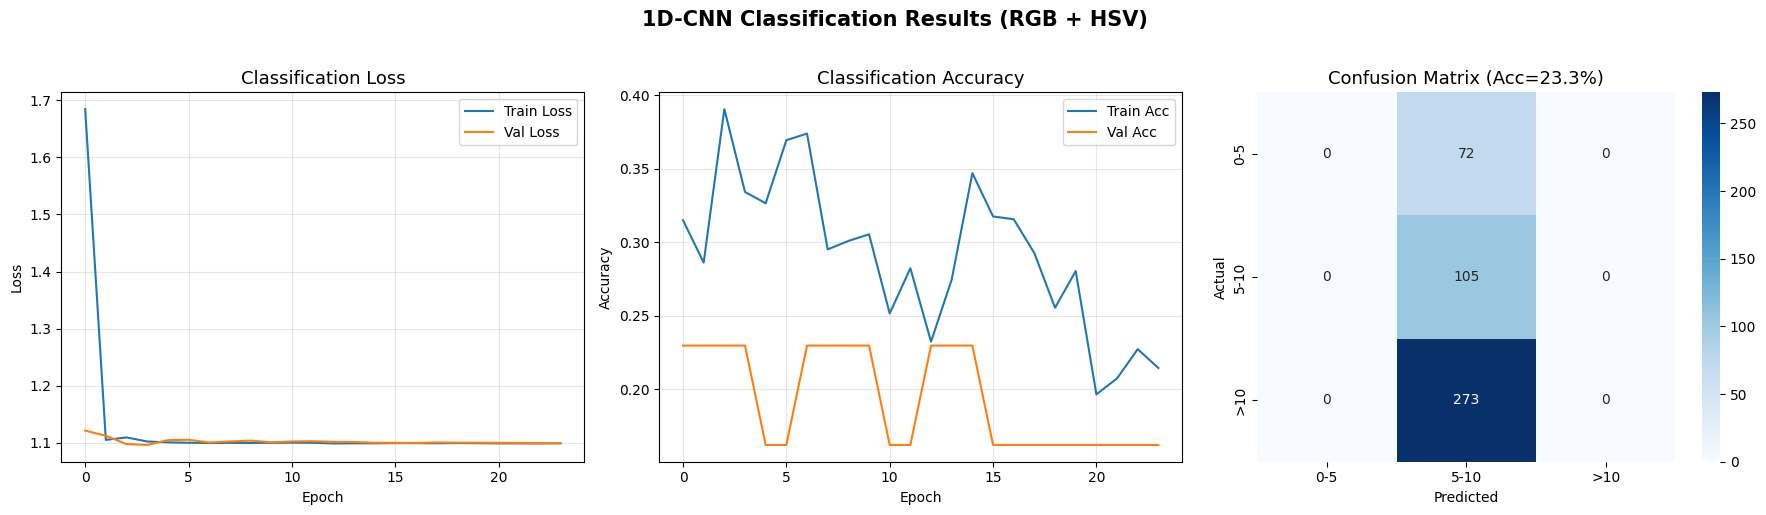

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# Cell 12: Classification Visualizations
# ═══════════════════════════════════════════════════════════════════
h_cls = history_cls.history

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training Loss
axes[0].plot(h_cls['loss'], label='Train Loss', linewidth=1.5)
axes[0].plot(h_cls['val_loss'], label='Val Loss', linewidth=1.5)
axes[0].set_title('Classification Loss', fontsize=13)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(h_cls['accuracy'], label='Train Acc', linewidth=1.5)
axes[1].plot(h_cls['val_accuracy'], label='Val Acc', linewidth=1.5)
axes[1].set_title('Classification Accuracy', fontsize=13)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0-5', '5-10', '>10'],
            yticklabels=['0-5', '5-10', '>10'], ax=axes[2])
axes[2].set_title(f'Confusion Matrix (Acc={accuracy*100:.1f}%)', fontsize=13)
axes[2].set_ylabel('Actual')
axes[2].set_xlabel('Predicted')

plt.suptitle('1D-CNN Classification Results (RGB + HSV)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Step 12: Summary & Comparison with Paper Results

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# Cell 13: Summary & Paper Comparison
# ═══════════════════════════════════════════════════════════════════
import json

print('\n' + '='*70)
print('    IMPLEMENTATION SUMMARY vs PAPER (Makhloughi, 2025)')
print('='*70)
print(f'\n  {"Metric":<25} {"Our Result":<15} {"Paper Result":<15}')
print(f'  {"-"*55}')
print(f'  {"RMSE (mg/dL)":<25} {rmse_test:<15.4f} {"1.13":<15}')
print(f'  {"MAE (mg/dL)":<25} {mae_test:<15.4f} {"0.89":<15}')
print(f'  {"R² Score":<25} {r2_test:<15.4f} {"0.91":<15}')
print(f'  {"Accuracy (%)":<25} {accuracy*100:<15.2f} {"96.87":<15}')
print(f'  {"Precision (%)":<25} {precision*100:<15.2f} {"94.75":<15}')
print(f'  {"Recall (%)":<25} {recall*100:<15.2f} {"92.69":<15}')
print(f'  {"F1-Score (%)":<25} {f1*100:<15.2f} {"93.72":<15}')
print('='*70)

print(f'\n  Configuration:')
print(f'    Architecture: 1D-CNN (4 conv blocks) — Table 2 of paper')
print(f'    Color spaces: RGB + HSV (best combination per paper)')
print(f'    Input shape:  ({TARGET_PIXELS}, 6) per image')
print(f'    Split:        70/10/20 (patient-level, stratified)')
print(f'    Optimizer:    Adam (LR={INITIAL_LR}, ReduceLROnPlateau)')
print(f'    Batch size:   {BATCH_SIZE}')
print(f'    Max epochs:   {EPOCHS} (with early stopping)')

# Save results
results = {
    'paper': 'Makhloughi (2025) - 10.1038/s41598-025-96100-9',
    'method': '1D-CNN with RGB+HSV color features',
    'regression': {
        'rmse': float(rmse_test),
        'mae': float(mae_test),
        'r2': float(r2_test),
        'epochs_trained': n_epochs
    },
    'classification': {
        'accuracy': float(accuracy),
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1),
        'epochs_trained': n_cls_epochs,
        'confusion_matrix': cm.tolist()
    },
    'data': {
        'total_samples': len(X_all),
        'train_samples': len(X_train),
        'val_samples': len(X_val),
        'test_samples': len(X_test),
        'train_patients': len(train_pats),
        'val_patients': len(val_pats),
        'test_patients': len(test_pats)
    },
    'hyperparameters': {
        'input_shape': list(X_train.shape[1:]),
        'batch_size': BATCH_SIZE,
        'initial_lr': INITIAL_LR,
        'max_epochs': EPOCHS
    }
}

results_path = os.path.join(SAVE_DIR, '1dcnn_paper_results.json')
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f'\n✅ Results saved to: {results_path}')


    IMPLEMENTATION SUMMARY vs PAPER (Makhloughi, 2025)

  Metric                    Our Result      Paper Result   
  -------------------------------------------------------
  RMSE (mg/dL)              5.1031          1.13           
  MAE (mg/dL)               4.1602          0.89           
  R² Score                  -0.0154         0.91           
  Accuracy (%)              23.33           96.87          
  Precision (%)             5.44            94.75          
  Recall (%)                23.33           92.69          
  F1-Score (%)              8.83            93.72          

  Configuration:
    Architecture: 1D-CNN (4 conv blocks) — Table 2 of paper
    Color spaces: RGB + HSV (best combination per paper)
    Input shape:  (4096, 6) per image
    Split:        70/10/20 (patient-level, stratified)
    Optimizer:    Adam (LR=0.01, ReduceLROnPlateau)
    Batch size:   32
    Max epochs:   150 (with early stopping)

✅ Results saved to: /Users/shubhbhateja/College/minor_proje